<a href="https://colab.research.google.com/github/ashishbhatta/Day_Ahead_Market_Simulation_in_Assume/blob/main/comparision%20actual%20and%20simulated%20Demand_and_supply_plot_for_june.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The data exported from grafana is used for the analysis. Data is stored in Market Summary EOM-data-2026-10-18 09_32_54.csv.

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
#url for June result
url = "https://github.com/ashishbhatta/Day_Ahead_Market_Simulation_in_Assume/raw/refs/heads/main/Grafana_output/Market%20Summary%20EOM-data-2026-10-18%2019_00_55.csv"
df = pd.read_csv(url)
#Url for actual MCP and MCV from IEX for June
url = "https://github.com/ashishbhatta/Day_Ahead_Market_Simulation_in_Assume/raw/refs/heads/main/inputs/June%20actual%20MCP%20and%20MCV.csv"
df2 = pd.read_csv(url)
df.head()

,Time,Demand volume,Price,Supply volume
0,2026-06-01 02:00:00,6.18 GW,6190 €/MWh,6.18 GW
1,2026-06-01 02:30:00,6.01 GW,6190 €/MWh,6.01 GW
2,2026-06-01 03:00:00,5.02 GW,6073 €/MWh,5.02 GW
3,2026-06-01 03:30:00,5.03 GW,6132 €/MWh,5.03 GW
4,2026-06-01 04:00:00,4.17 GW,6073 €/MWh,4.17 GW


In [ ]:
#The data in Price column is in format #### €/Mwh. The term €/Mwh is removed from this

df["Price"] = pd.to_numeric(
    df["Price"].astype(str).str.replace(r"\s*€/MWh", "", regex=True).str.strip()
)
df["Demand volume"] = pd.to_numeric(
    df["Demand volume"].astype(str).str.replace(r"\s*GW", "", regex=True).str.strip()
)
df["Supply volume"] = pd.to_numeric(
    df["Supply volume"].astype(str).str.replace(r"\s*GW", "", regex=True).str.strip()
)

df.head()
#print(df["Price"].dtype) used for checking data type

,Time,Demand volume,Price,Supply volume
0,2026-06-01 02:00:00,6.18,6190,6.18
1,2026-06-01 02:30:00,6.01,6190,6.01
2,2026-06-01 03:00:00,5.02,6073,5.02
3,2026-06-01 03:30:00,5.03,6132,5.03
4,2026-06-01 04:00:00,4.17,6073,4.17


Add the columns from df2 (actual value) to df (result) to plot and compare

In [ ]:
df["Time"] = pd.to_datetime(df["Time"])
df["Demand volume"] =  df["Demand volume"]*1000
df["Supply volume"] = df["Supply volume"]*1000
df2["DateTime"] = pd.to_datetime(df2["DateTime"])

# Match each row in df with the corresponding timestamp in df2
df = df.merge(
    df2[["DateTime", "MCP (Rs/MWh) *", "MCV (MW)"]],
    left_on="Time",
    right_on="DateTime",
    how="left"
)

# Remove the duplicate timestamp column
df = df.drop(columns=["DateTime"])

print(df.head())


                 Time  Demand volume  Price  Supply volume  MCP (Rs/MWh) *  \
0 2026-06-01 02:00:00         6180.0   6190         6180.0         3604.71   
1 2026-06-01 02:30:00         6010.0   6190         6010.0         3599.88   
2 2026-06-01 03:00:00         5020.0   6073         5020.0         3499.51   
3 2026-06-01 03:30:00         5030.0   6132         5030.0         3432.44   
4 2026-06-01 04:00:00         4170.0   6073         4170.0         3571.07   

   MCV (MW)  
0    7316.2  
1    7146.9  
2    6539.7  
3    6244.8  
4    6685.5  


Plot for demand volume and price wrt time

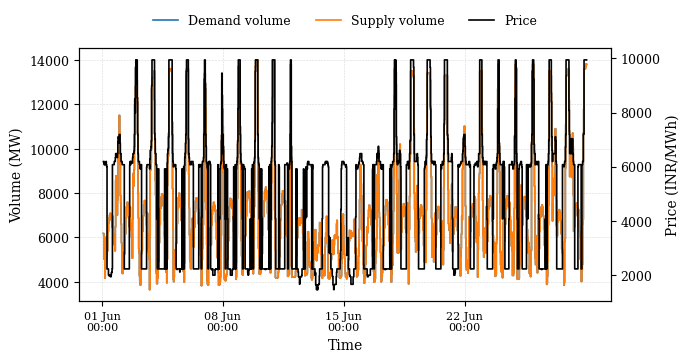

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Convert Time column to datetime
df["Time"] = pd.to_datetime(df["Time"])

# Publication-quality settings
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax1 = plt.subplots(figsize=(7.0, 3.8))

# Demand and supply volume (left y-axis)
ax1.step(
    df["Time"], df["Demand volume"],
    where="post", linestyle="-", linewidth=1.2,
    label="Demand volume"
)

ax1.step(
    df["Time"], df["Supply volume"],
    where="post", linestyle="-", linewidth=1.2,
    label="Supply volume"
)

ax1.set_xlabel("Time")
ax1.set_ylabel("Volume (MW)")
ax1.grid(True, linestyle="--", linewidth=0.4, alpha=0.5)
ax1.set_axisbelow(True)

# Price (right y-axis)
ax2 = ax1.twinx()

ax2.step(
    df["Time"], df["Price"],
    where="post", linestyle="-", linewidth=1.2,
    color="black", label="Price"
)

ax2.set_ylabel("Price (INR/MWh)")

# Format datetime ticks
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
ax1.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=8))
ax1.tick_params(axis="both", direction="out", width=0.8)
ax2.tick_params(axis="y", direction="out", width=0.8)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=3,
    frameon=False
)

fig.tight_layout()

# Export publication files
fig.savefig("market_plot.pdf", bbox_inches="tight")
fig.savefig("market_plot.tiff", dpi=600, bbox_inches="tight")
fig.savefig("market_plot.png", dpi=600, bbox_inches="tight")

plt.show()

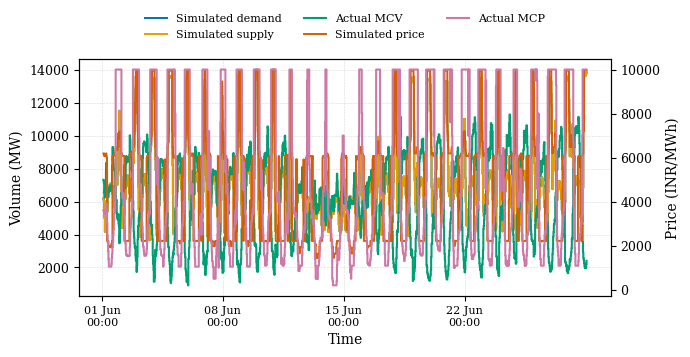

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df["Time"] = pd.to_datetime(df["Time"])

# Publication-quality settings
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax1 = plt.subplots(figsize=(7.0, 3.8))

# Distinct, colorblind-friendly colors
c_demand = "#0072B2"  # Blue
c_supply = "#E69F00"  # Orange
c_mcv = "#009E73"     # Green
c_price = "#D55E00"   # Vermilion
c_mcp = "#CC79A7"     # Purple-pink

# Left y-axis: volumes
ax1.step(
    df["Time"], df["Demand volume"],
    where="post", linestyle="-", linewidth=1.4,
    color=c_demand, label="Simulated demand"
)

ax1.step(
    df["Time"], df["Supply volume"],
    where="post", linestyle="-", linewidth=1.4,
    color=c_supply, label="Simulated supply"
)

ax1.step(
    df["Time"], df["MCV (MW)"],
    where="post", linestyle="-", linewidth=1.5,
    color=c_mcv, label="Actual MCV"
)

ax1.set_xlabel("Time")
ax1.set_ylabel("Volume (MW)")
ax1.grid(True, linestyle="--", linewidth=0.4, color="0.85")
ax1.set_axisbelow(True)

# Right y-axis: prices
ax2 = ax1.twinx()

ax2.step(
    df["Time"], df["Price"],
    where="post", linestyle="-", linewidth=1.4,
    color=c_price, label="Simulated price"
)

ax2.step(
    df["Time"], df["MCP (Rs/MWh) *"],
    where="post", linestyle="-", linewidth=1.5,
    color=c_mcp, label="Actual MCP"
)

ax2.set_ylabel("Price (INR/MWh)")

# Format datetime ticks
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
ax1.xaxis.set_major_locator(
    mdates.AutoDateLocator(minticks=4, maxticks=8)
)

ax1.tick_params(axis="both", direction="out", width=0.8)
ax2.tick_params(axis="y", direction="out", width=0.8)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.23),
    ncol=3,
    frameon=False
)

fig.tight_layout()

# Export publication files
fig.savefig("market_plot.pdf", bbox_inches="tight")
fig.savefig("market_plot.tiff", dpi=600, bbox_inches="tight")
fig.savefig("market_plot.png", dpi=600, bbox_inches="tight")

plt.show()


In [ ]:

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Convert Time to datetime
df["Time"] = pd.to_datetime(df["Time"])

# Create interactive chart with two y-axes
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Color palette
c_demand = "#0072B2"  # Blue
c_supply = "#E69F00"  # Orange
c_mcv = "#009E73"     # Green
c_price = "#D55E00"   # Vermilion
c_mcp = "#CC79A7"     # Purple-pink

# Left y-axis: volume
fig.add_trace(
    go.Scatter(
        x=df["Time"], y=df["Demand volume"],
        mode="lines", name="Simulated demand",
        line=dict(color=c_demand, width=2),
        hovertemplate="Time: %{x|%d %b %Y %H:%M}<br>Demand: %{y:.2f} MW<extra></extra>"
    ),
    secondary_y=False
)

fig.add_trace(
    go.Scatter(
        x=df["Time"], y=df["Supply volume"],
        mode="lines", name="Simulated supply",
        line=dict(color=c_supply, width=2),
        hovertemplate="Time: %{x|%d %b %Y %H:%M}<br>Supply: %{y:.2f} MW<extra></extra>"
    ),
    secondary_y=False
)

fig.add_trace(
    go.Scatter(
        x=df["Time"], y=df["MCV (MW)"],
        mode="lines", name="Actual MCV",
        line=dict(color=c_mcv, width=2),
        hovertemplate="Time: %{x|%d %b %Y %H:%M}<br>Actual MCV: %{y:.2f} MW<extra></extra>"
    ),
    secondary_y=False
)

# Right y-axis: price
fig.add_trace(
    go.Scatter(
        x=df["Time"], y=df["Price"],
        mode="lines", name="Simulated price",
        line=dict(color=c_price, width=2),
        hovertemplate="Time: %{x|%d %b %Y %H:%M}<br>Simulated price: INR %{y:.2f}/MWh<extra></extra>"
    ),
    secondary_y=True
)

fig.add_trace(
    go.Scatter(
        x=df["Time"], y=df["MCP (Rs/MWh) *"],
        mode="lines", name="Actual MCP",
        line=dict(color=c_mcp, width=2),
        hovertemplate="Time: %{x|%d %b %Y %H:%M}<br>Actual MCP: INR %{y:.2f}/MWh<extra></extra>"
    ),
    secondary_y=True
)

# Layout
fig.update_layout(
    title="Simulated and Actual Electricity Market Results",
    template="plotly_white",
    width=1100,
    height=600,
    hovermode="x unified",
    font=dict(family="serif", size=13),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5
    ),
    margin=dict(l=80, r=80, t=110, b=80)
)

fig.update_xaxes(
    title_text="Time",
    showgrid=True,
    rangeslider_visible=True
)

fig.update_yaxes(
    title_text="Volume (MW)",
    secondary_y=False,
    showgrid=True
)

fig.update_yaxes(
    title_text="Price (INR/MWh)",
    secondary_y=True,
    showgrid=False
)

# Export interactive chart to HTML
fig.write_html(
    "market_plot.html",
    include_plotlyjs=True,
    full_html=True
)

fig.show()

print("Interactive chart saved as market_plot.html")


Interactive chart saved as market_plot.html


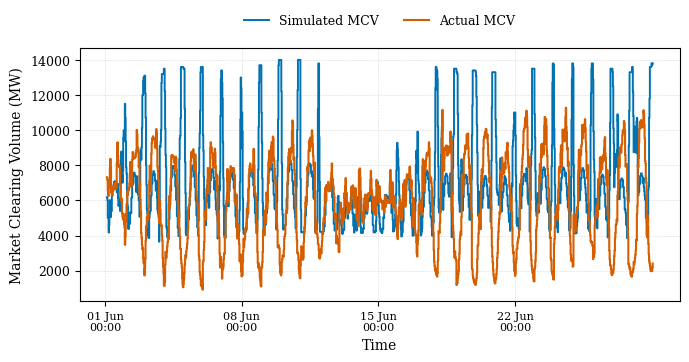

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df["Time"] = pd.to_datetime(df["Time"])

# Publication-quality settings
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(7.0, 3.8))

# Distinct colors
c_simulated = "#0072B2"  # Blue
c_actual = "#D55E00"     # Vermilion

# Simulated MCV: using simulated supply volume
ax.step(
    df["Time"], df["Supply volume"],
    where="post", linestyle="-", linewidth=1.4,
    color=c_simulated, label="Simulated MCV"
)

# Actual MCV
ax.step(
    df["Time"], df["MCV (MW)"],
    where="post", linestyle="-", linewidth=1.5,
    color=c_actual, label="Actual MCV"
)

ax.set_xlabel("Time")
ax.set_ylabel("Market Clearing Volume (MW)")
ax.grid(True, linestyle="--", linewidth=0.4, color="0.85")
ax.set_axisbelow(True)

# Format datetime ticks
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
ax.xaxis.set_major_locator(
    mdates.AutoDateLocator(minticks=4, maxticks=8)
)
ax.tick_params(axis="both", direction="out", width=0.8)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=2,
    frameon=False
)

fig.tight_layout()

# Export publication files
fig.savefig("mcv_comparison.pdf", bbox_inches="tight")
fig.savefig("mcv_comparison.tiff", dpi=600, bbox_inches="tight")
fig.savefig("mcv_comparison.png", dpi=600, bbox_inches="tight")

plt.show()

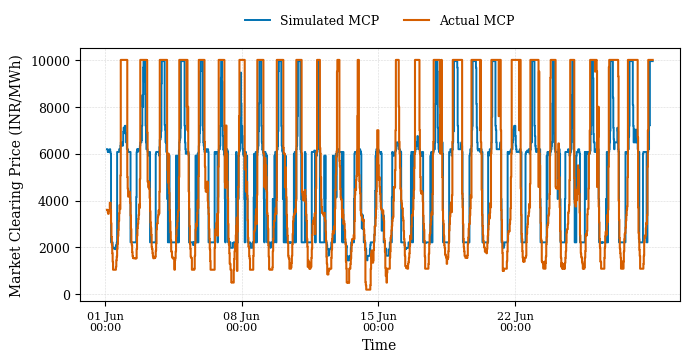

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df["Time"] = pd.to_datetime(df["Time"])

# Publication-quality settings
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(7.0, 3.8))

# Distinct colors
c_simulated = "#0072B2"  # Blue
c_actual = "#D55E00"     # Vermilion

# Simulated MCP
ax.step(
    df["Time"], df["Price"],
    where="post", linestyle="-", linewidth=1.4,
    color=c_simulated, label="Simulated MCP"
)

# Actual MCP
ax.step(
    df["Time"], df["MCP (Rs/MWh) *"],
    where="post", linestyle="-", linewidth=1.5,
    color=c_actual, label="Actual MCP"
)

ax.set_xlabel("Time")
ax.set_ylabel("Market Clearing Price (INR/MWh)")
ax.grid(True, linestyle="--", linewidth=0.4, color="0.85")
ax.set_axisbelow(True)

# Format datetime ticks
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
ax.xaxis.set_major_locator(
    mdates.AutoDateLocator(minticks=4, maxticks=8)
)
ax.tick_params(axis="both", direction="out", width=0.8)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=2,
    frameon=False
)

fig.tight_layout()

# Export publication files
fig.savefig("mcp_comparison.pdf", bbox_inches="tight")
fig.savefig("mcp_comparison.tiff", dpi=600, bbox_inches="tight")
fig.savefig("mcp_comparison.png", dpi=600, bbox_inches="tight")

plt.show()